
# Regularization: Ridge & Lasso

## 1. Why Regularization?

- **Problem:** A model with large coefficients may overfit training data (high variance).
- **Solution:** Add a penalty to RSS that shrinks coefficients toward zero.
- **Tradeoff:** Lower variance, potentially higher bias → better test MSE.

## 2. Ridge Regression (L2)

$$
\boxed{
\hat{\beta}^{Ridge} =
\arg\min_{\beta}
\left[
RSS + \lambda\sum_{j=1}^{p}\beta_j^2
\right]
}
$$

- Penalizes the **squared coefficients**.
- Shrinks coefficients toward zero, but generally **not exactly zero**.
- Keeps all predictors in the model.
- Useful for reducing overfitting.

## 3. Lasso Regression (L1)

$$
\boxed{
\hat{\beta}^{Lasso} =
\arg\min_{\beta}
\left[
RSS + \lambda\sum_{j=1}^{p}|\beta_j|
\right]
}
$$

- Penalizes the **absolute values** of coefficients.
- Can shrink coefficients to **exactly zero**.
- Performs **automatic feature selection**.
- Useful when only a subset of predictors is relevant.

**Note:** The intercept $\beta_0$ is typically not penalized.

## 4. Role of Lambda ($\lambda$)

- $\lambda = 0$: Ordinary Least Squares (no regularization).
- $\lambda \uparrow$: More shrinkage → less flexibility → lower variance, higher bias.
- $\lambda$ too large: Underfitting.
- **Choose $\lambda$ using K-fold cross-validation** to minimize validation MSE.

## 5. Ridge vs. Lasso

| Feature | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Penalty | $\sum \beta_j^2$ | $\sum |\beta_j|$ |
| Shrinks coefficients | Yes | Yes |
| Exactly zero coefficients | Generally no | Yes |
| Feature selection | No | Yes |
| Reduces variance | Yes | Yes |

## Key Takeaways

1. Regularization = RSS + penalty.
2. Ridge shrinks coefficients but generally keeps all predictors.
3. Lasso can eliminate predictors by setting coefficients to zero.
4. Increasing $\lambda$ reduces model flexibility.
5. Cross-validation chooses the optimal $\lambda$ for prediction.

## Quick Understanding Check

1. Why does increasing $\lambda$ typically reduce variance?
2. Why can Lasso perform feature selection but Ridge cannot?
3. What happens when $\lambda = 0$?
4. Why shouldn't we always choose a very large $\lambda$?


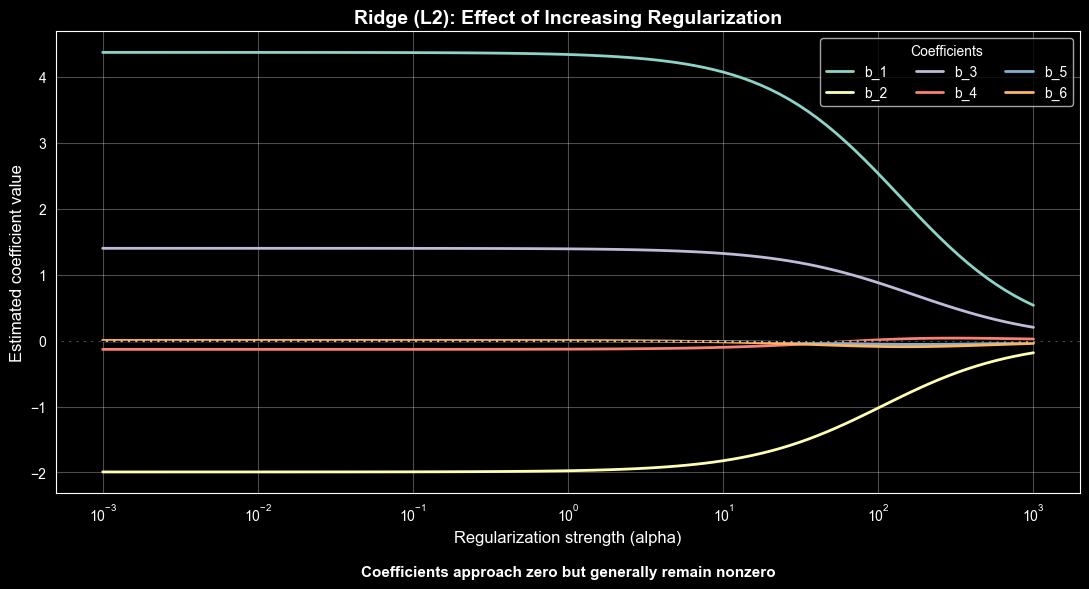

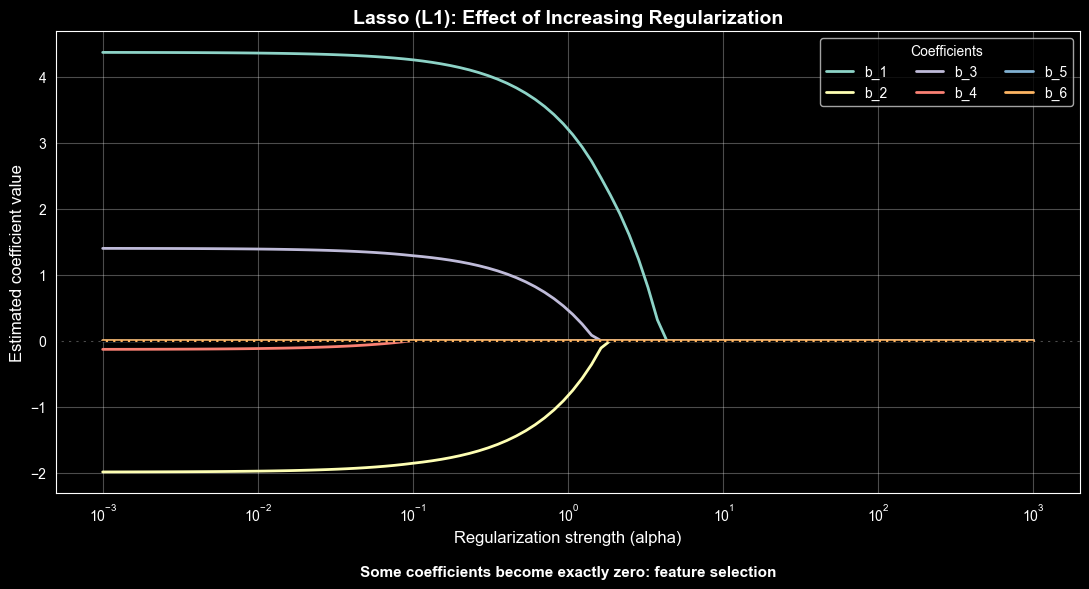

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

X = rng.normal(size=(150, 6))
y = 4*X[:, 0] - 2*X[:, 1] + 1.5*X[:, 2] + rng.normal(size=150)

X = StandardScaler().fit_transform(X)
lambdas = np.logspace(-3, 3, 100)

for Model, name in [(Ridge, "Ridge (L2)"), (Lasso, "Lasso (L1)")]:
    coefficients = []

    for lam in lambdas:
        model = Model(alpha=lam, max_iter=20000)
        model.fit(X, y)
        coefficients.append(model.coef_)

    coefficients = np.array(coefficients)

    fig, ax = plt.subplots(figsize=(11, 6))

    for j in range(X.shape[1]):
        ax.plot(lambdas, coefficients[:, j],
                linewidth=2, label=f"b_{j+1}")

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xscale("log")

    ax.set_title(
        f"{name}: Effect of Increasing Regularization",
        fontsize=14, weight="bold"
    )
    ax.set_xlabel("Regularization strength (alpha)", fontsize=12)
    ax.set_ylabel("Estimated coefficient value", fontsize=12)
    ax.legend(title="Coefficients", fontsize=10, ncol=3)
    ax.grid(alpha=0.3)

    takeaway = (
        "Coefficients approach zero but generally remain nonzero"
        if name.startswith("Ridge")
        else "Some coefficients become exactly zero: feature selection"
    )

    ax.text(
        0.5, -0.18, takeaway,
        transform=ax.transAxes,
        ha="center", fontsize=11, weight="bold"
    )

    plt.tight_layout()
    plt.show()
